In [1]:
import wfdb
import numpy as np
import os
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

In [2]:

DATA_PATH = r"C:\Users\anany\Documents\major project\mitdb"  

BEAT_LEN = 187

# MIT-BIH record numbers
RECORDS = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

# AAMI class mapping
LABEL_MAP = {
    'N':'N','L':'N','R':'N','e':'N','j':'N',
    'A':'S','a':'S','J':'S','S':'S',
    'V':'V','E':'V',
    'F':'F',
    '/':'Q','f':'Q','Q':'Q'
}

beats, labels = [], []

for rec in RECORDS:
    path = os.path.join(DATA_PATH, rec)
    if not os.path.exists(path + '.dat'):
        continue
    try:
        record = wfdb.rdrecord(path)
        annotation = wfdb.rdann(path, 'atr')
        signal = record.p_signal[:, 0]
        
        for i, (idx, sym) in enumerate(zip(annotation.sample, annotation.symbol)):
            if sym not in LABEL_MAP:
                continue
            start = idx - BEAT_LEN // 2
            end = start + BEAT_LEN
            if start < 0 or end > len(signal):
                continue
            beat = signal[start:end]
            beat = (beat - np.mean(beat)) / (np.std(beat) + 1e-8)
            beats.append(beat)
            labels.append(LABEL_MAP[sym])
    except Exception as e:
        print(f"Skipping {rec}: {e}")

X = np.array(beats, dtype=np.float32)
y = np.array(labels)
print("Shape:", X.shape)
print("Class dist:", Counter(y))

Shape: (109468, 187)
Class dist: Counter({np.str_('N'): 90608, np.str_('Q'): 8042, np.str_('V'): 7235, np.str_('S'): 2781, np.str_('F'): 802})


In [3]:
le = LabelEncoder()
y_enc = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=42
)

# Reshape for Conv1d: (batch, channels, length)
X_train = torch.tensor(X_train).unsqueeze(1)
X_test  = torch.tensor(X_test).unsqueeze(1)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test  = torch.tensor(y_test,  dtype=torch.long)

train_ds = TensorDataset(X_train, y_train)
test_ds  = TensorDataset(X_test,  y_test)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=64)
print("Train:", len(train_ds), "| Test:", len(test_ds))

Train: 87574 | Test: 21894


In [ ]:
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, out_ch=32):
        super().__init__()
        self.bottleneck = nn.Conv1d(in_ch, 32, 1)
        self.c1 = nn.Conv1d(32, out_ch, kernel_size=9,  padding='same')
        self.c2 = nn.Conv1d(32, out_ch, kernel_size=19, padding='same')
        self.c3 = nn.Conv1d(32, out_ch, kernel_size=39, padding='same')
        self.mp = nn.MaxPool1d(3, stride=1, padding=1)
        self.cp = nn.Conv1d(in_ch, out_ch, 1)
        self.bn = nn.BatchNorm1d(out_ch * 4)
        self.relu = nn.ReLU()

    def forward(self, x):
        b = self.bottleneck(x)
        out = torch.cat([self.c1(b), self.c2(b), self.c3(b),
                         self.cp(self.mp(x))], dim=1)
        return self.relu(self.bn(out))

class InceptionTime(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.b1 = InceptionBlock(1,   32)
        self.b2 = InceptionBlock(128, 32)
        self.b3 = InceptionBlock(128, 32)
        self.b4 = InceptionBlock(128, 32)
        self.b5 = InceptionBlock(128, 32)
        self.b6 = InceptionBlock(128, 32)
        self.gap = nn.AdaptiveAvgPool1d(1)
        self.fc  = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.b1(x); x = self.b2(x); x = self.b3(x)
        x = self.b4(x); x = self.b5(x); x = self.b6(x)
        return self.fc(self.gap(x).squeeze(-1))

model = InceptionTime(num_classes=len(le.classes_))
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)
print("Model ready on", device)
print("Classes:", le.classes_)

Model ready on cpu
Classes: ['F' 'N' 'Q' 'S' 'V']


In [ ]:
# Class weights for imbalance
counts = Counter(y_train.numpy())
total = sum(counts.values())
weights = torch.tensor([total / counts[i] for i in range(len(le.classes_))],
                        dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

EPOCHS = 6
for epoch in range(EPOCHS):
    model.train()
    total_loss, correct = 0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (out.argmax(1) == yb).sum().item()
    scheduler.step()
    acc = correct / len(train_ds) * 100
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Loss: {total_loss:.3f} | Acc: {acc:.1f}%")

Epoch 01/6 | Loss: 596.758 | Acc: 80.3%
Epoch 02/6 | Loss: 359.297 | Acc: 89.6%
Epoch 03/6 | Loss: 300.957 | Acc: 90.9%
Epoch 04/6 | Loss: 255.856 | Acc: 92.5%
Epoch 05/6 | Loss: 236.394 | Acc: 93.0%
Epoch 06/6 | Loss: 172.560 | Acc: 94.9%


In [6]:
model.eval()
all_preds, all_true = [], []

with torch.no_grad():
    for xb, yb in test_dl:
        xb = xb.to(device)
        preds = model(xb).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(yb.numpy())

print(classification_report(
    all_true,
    all_preds,
    target_names=le.classes_
))

              precision    recall  f1-score   support

           F       0.23      0.97      0.38       160
           N       1.00      0.94      0.97     18122
           Q       0.98      1.00      0.99      1609
           S       0.59      0.90      0.72       556
           V       0.88      0.96      0.92      1447

    accuracy                           0.95     21894
   macro avg       0.74      0.96      0.79     21894
weighted avg       0.97      0.95      0.96     21894



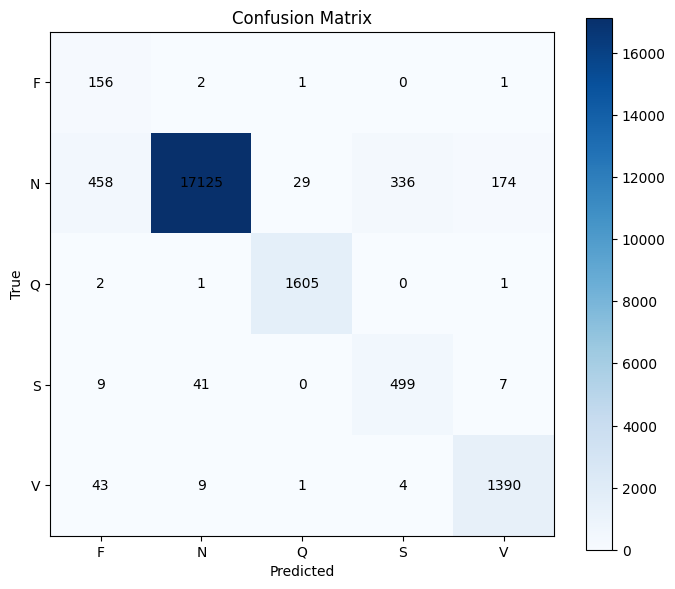

In [7]:
cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize=(7,6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]),
                 ha='center', va='center')

plt.xticks(range(len(le.classes_)), le.classes_)
plt.yticks(range(len(le.classes_)), le.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.savefig("confusion_matrix_numbers.png", dpi=150)
plt.show()

c:\Users\anany\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\module.py:1870: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


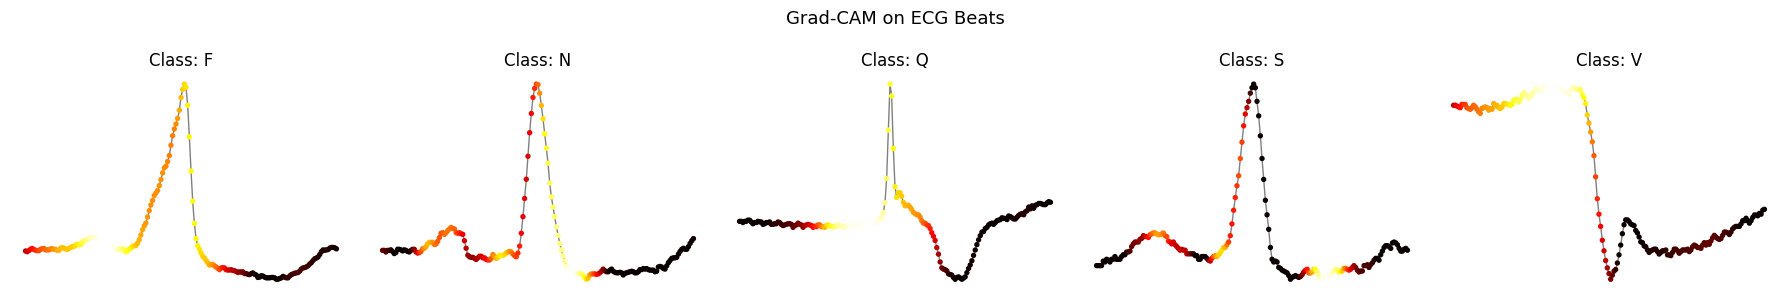

Done! Saved gradcam_ecg.png


In [8]:
def grad_cam_1d(model, x_input, target_class):
    model.eval()
    x = x_input.unsqueeze(0).to(device)
    x.requires_grad_(True)
    
    activations, gradients = [], []
    
    def fwd_hook(m, inp, out): activations.append(out)
    def bwd_hook(m, gi, go):   gradients.append(go[0])
    
    h1 = model.b6.bn.register_forward_hook(fwd_hook)
    h2 = model.b6.bn.register_backward_hook(bwd_hook)
    
    out = model(x)
    model.zero_grad()
    out[0, target_class].backward()
    
    h1.remove(); h2.remove()
    
    act = activations[0].squeeze().detach().cpu()
    grad = gradients[0].squeeze().detach().cpu()
    weights = grad.mean(dim=1)
    cam = (weights.unsqueeze(1) * act).sum(0)
    cam = torch.relu(cam)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.numpy()

# Visualize one beat per class
fig, axes = plt.subplots(1, len(le.classes_), figsize=(18, 3))
for i, cls in enumerate(le.classes_):
    idx = np.where(np.array(all_true) == i)[0]
    if len(idx) == 0: continue
    sample = X_test[idx[0]]
    cam = grad_cam_1d(model, sample, i)
    sig = sample.squeeze().numpy()
    t = np.arange(len(sig))
    axes[i].plot(sig, color='gray', lw=1)
    axes[i].scatter(t, sig, c=cam, cmap='hot', s=8, zorder=3)
    axes[i].set_title(f"Class: {cls}")
    axes[i].axis('off')
plt.suptitle("Grad-CAM on ECG Beats", fontsize=13)
plt.tight_layout()
plt.savefig("gradcam_ecg.png", dpi=150)
plt.show()
print("Done! Saved gradcam_ecg.png")